<a href="https://colab.research.google.com/github/VielF/ColabProjects/blob/main/Pr%C3%A1tica_Processamento_Morfol%C3%B3gico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Universidade do Vale do Itajaí<br>
Escola Politécnica<br>
Processamento Digital de Sinais: Imagens

# Exercício Avalitivo de Processamento Morfológico

### Tutoriais da OpenCV

- https://docs.opencv.org/master/d9/df8/tutorial_root.html
- https://www.geeksforgeeks.org/opencv-python-tutorial/

## Processamento Morfológico
#### Obs: Utilize imagens em preto e branco.


### Erosão e Dilatação

1. Implemente a sua própria versão da erosão em formato de função, com capacidade de trabalhar com diferentes elementos estruturantes (tamanho e forma) e aplique o algoritmos na na figura ImagensMorfologia/Fig0905(a)(wirebond-mask)
2. Implemente a sua própria versão da dilatação em formato de função, com capacidade de trabalhar com diferentes elementos estruturantes (tamanho e forma) e aplique o algoritmos na na figura ImagensMorfologia/Fig0907(a)(text_gaps_1_and_2_pixels) 
4. Relate as observações visíveis nas imagens de saída com os processamentos aplicados, descrevendo o comportamento visual em relação as bordas, junção, perda de informação e mlhoria na qualidade visual.
5. Aplique o seu algoritmo de detecção de borda (roberts ou sobel) a imagem ImagensMorfologia/Fig0905(a)(wirebond-mask) antes e depois de utilizar a dilatação/erosão e relate os resultados.

#### Dicas
 - Você pode adicionar ruído nas imagens usando a função random_noise: `from skimage.util import random_noise`. Cuidado com o retorno da função, talvez seja necessário regularizar a mesma novamente para o intervalo de 0 à 255. O ruído pode ser intensificado ou excluído com processamento morfológico.

### Preparação dos dados

As imagens ficam no repositório do professor, em `dataset/OperacaoMorfologia/`. A célula abaixo baixa os três arquivos
usados no notebook para a pasta `ImagensMorfologia/`, que é o caminho que o código já usa. Assim o notebook roda
do zero no Colab, sem precisar subir nada à mão.

In [2]:
import os
import urllib.parse
import urllib.request

BASE = "https://raw.githubusercontent.com/VielF/ColabProjects/main/dataset/OperacaoMorfologia/"
ARQUIVOS = [
    "Fig0905(a)(wirebond-mask).tif",
    "Fig0907(a)(text_gaps_1_and_2_pixels).tif",
    "Fig0911(a)(noisy_fingerprint).tif",
]

os.makedirs("ImagensMorfologia", exist_ok=True)
for nome in ARQUIVOS:
    destino = os.path.join("ImagensMorfologia", nome)
    if not os.path.exists(destino):
        urllib.request.urlretrieve(BASE + urllib.parse.quote(nome), destino)
    print("ok:", destino)


ok: ImagensMorfologia\Fig0905(a)(wirebond-mask).tif
ok: ImagensMorfologia\Fig0907(a)(text_gaps_1_and_2_pixels).tif
ok: ImagensMorfologia\Fig0911(a)(noisy_fingerprint).tif


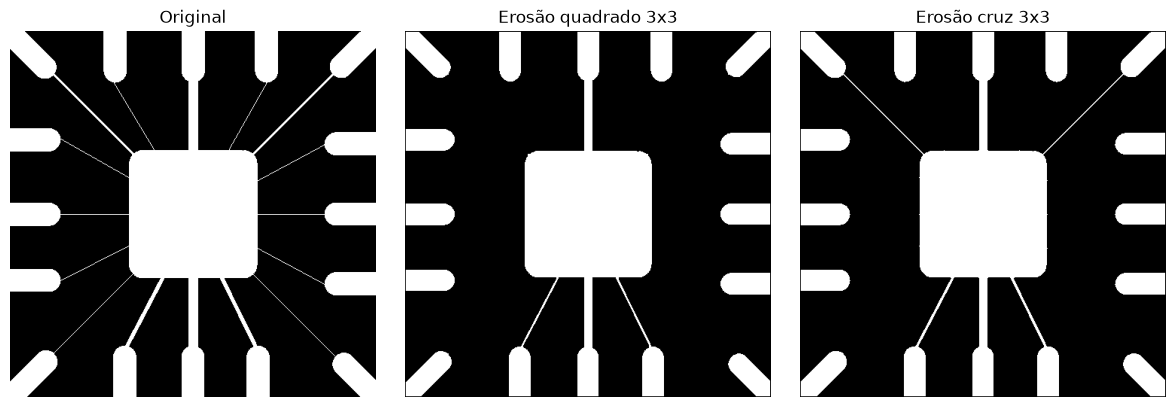

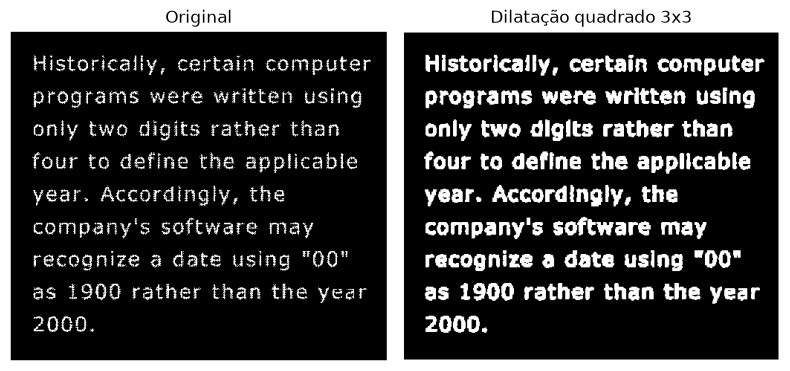

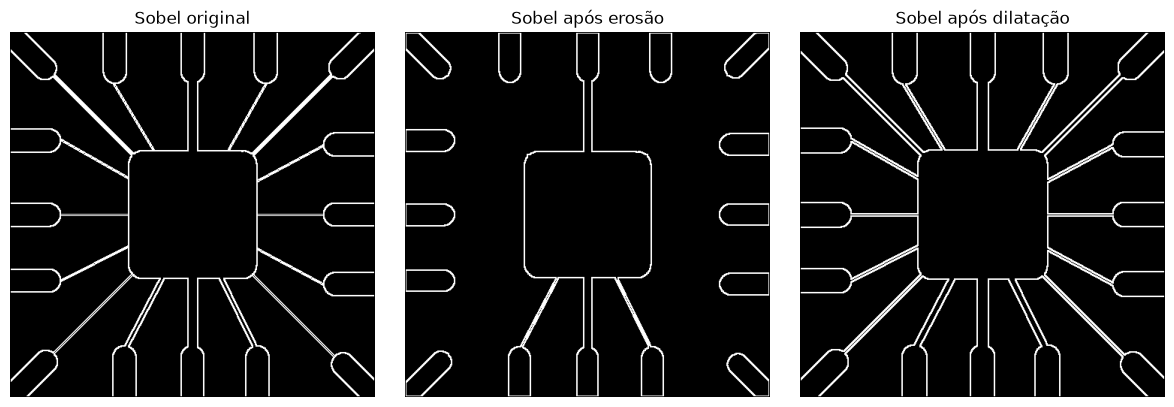

In [3]:
import math
from PIL import Image

import matplotlib.pyplot as plt
import numpy as np


def carregar(caminho):
    imagem = Image.open(caminho).convert("L")
    return np.array(imagem, dtype=np.uint8)


def erosao(imagem, elemento):
    altura, largura = imagem.shape
    eh = len(elemento)
    ew = len(elemento[0])
    oy = eh // 2
    ox = ew // 2
    saida = np.zeros((altura, largura), dtype=np.uint8)
    for y in range(altura):
        for x in range(largura):
            cabe = True
            for i in range(eh):
                yy = y + i - oy
                for j in range(ew):
                    if elemento[i][j] == 0:
                        continue
                    xx = x + j - ox
                    if yy < 0 or xx < 0 or yy >= altura or xx >= largura or imagem[yy, xx] == 0:
                        cabe = False
                        break
                if not cabe:
                    break
            if cabe:
                saida[y, x] = 255
    return saida


def dilatacao(imagem, elemento):
    altura, largura = imagem.shape
    eh = len(elemento)
    ew = len(elemento[0])
    oy = eh // 2
    ox = ew // 2
    saida = np.zeros((altura, largura), dtype=np.uint8)
    for y in range(altura):
        for x in range(largura):
            acertou = False
            for i in range(eh):
                yy = y + i - oy
                for j in range(ew):
                    if elemento[i][j] == 0:
                        continue
                    xx = x + j - ox
                    if 0 <= yy < altura and 0 <= xx < largura and imagem[yy, xx] > 0:
                        acertou = True
                        break
                if acertou:
                    break
            if acertou:
                saida[y, x] = 255
    return saida


def abertura(imagem, elemento):
    return dilatacao(erosao(imagem, elemento), elemento)


def fechamento(imagem, elemento):
    return erosao(dilatacao(imagem, elemento), elemento)


def sobel(imagem):
    gx_k = ((-1, 0, 1), (-2, 0, 2), (-1, 0, 1))
    gy_k = ((-1, -2, -1), (0, 0, 0), (1, 2, 1))
    altura, largura = imagem.shape
    saida = np.zeros((altura, largura), dtype=np.uint8)
    for y in range(1, altura - 1):
        for x in range(1, largura - 1):
            gx = 0
            gy = 0
            for i in range(3):
                for j in range(3):
                    pixel = int(imagem[y + i - 1, x + j - 1])
                    gx += gx_k[i][j] * pixel
                    gy += gy_k[i][j] * pixel
            magnitude = math.sqrt(gx * gx + gy * gy)
            if magnitude > 255:
                magnitude = 255
            saida[y, x] = int(magnitude)
    return saida


def mostrar(imagens, titulos):
    n = len(imagens)
    fig, eixos = plt.subplots(1, n, figsize=(4 * n, 4))
    if n == 1:
        eixos = [eixos]
    for eixo, imagem, titulo in zip(eixos, imagens, titulos):
        eixo.imshow(imagem, cmap="gray", vmin=0, vmax=255)
        eixo.set_title(titulo)
        eixo.axis("off")
    plt.tight_layout()
    plt.show()


quadrado = [
    [1, 1, 1],
    [1, 1, 1],
    [1, 1, 1],
]
cruz = [
    [0, 1, 0],
    [1, 1, 1],
    [0, 1, 0],
]

wirebond = carregar("ImagensMorfologia/Fig0905(a)(wirebond-mask).tif")
erosao_quadrado = erosao(wirebond, quadrado)
erosao_cruz = erosao(wirebond, cruz)
dilatacao_wirebond = dilatacao(wirebond, quadrado)

mostrar(
    [wirebond, erosao_quadrado, erosao_cruz],
    ["Original", "Erosão quadrado 3x3", "Erosão cruz 3x3"],
)

texto = carregar("ImagensMorfologia/Fig0907(a)(text_gaps_1_and_2_pixels).tif")
dilatacao_texto = dilatacao(texto, quadrado)
mostrar(
    [texto, dilatacao_texto],
    ["Original", "Dilatação quadrado 3x3"],
)

mostrar(
    [sobel(wirebond), sobel(erosao_quadrado), sobel(dilatacao_wirebond)],
    ["Sobel original", "Sobel após erosão", "Sobel após dilatação"],
)


Na wirebond, a erosão com quadrado 3×3 recua a borda e apaga os fios de um pixel, na horizontal, na vertical e na diagonal. Sobram os pads e os traços grossos, com perda do detalhe fino. A cruz 3×3 tem o mesmo tamanho e outra forma: apaga os fios diagonais e ainda preserva parte dos fios horizontais e verticais. No texto, a dilatação com quadrado 3×3 engrossa as letras, fecha as falhas de 1 e 2 pixels e junta caracteres vizinhos. A continuidade do traço melhora e a separação entre as letras piora.

O Sobel na imagem original marca o contorno dos pads e dos fios finos. Depois da erosão quadrada, as bordas desses fios somem junto com eles. Depois da dilatação, o contorno segue o traço mais grosso, e ligações que estavam separadas passam a formar uma borda só.


### Abertura e Fechamento

5. Implemente a sua versão do algoritmo de abertura em forma de função com capacidade de trabalhar com diferentes elementos estruturantes (tamanho e forma)
6. Implemente a sua versão do algoritmo de fechamento em forma de função com capacidade de trabalhar com diferentes elementos estruturantes (tamanho e forma)
7. Aplique o processamento indicado na image abaixo usando a figura ImagensMorfologia/Fig0911(a)(noisy_fingerprint)

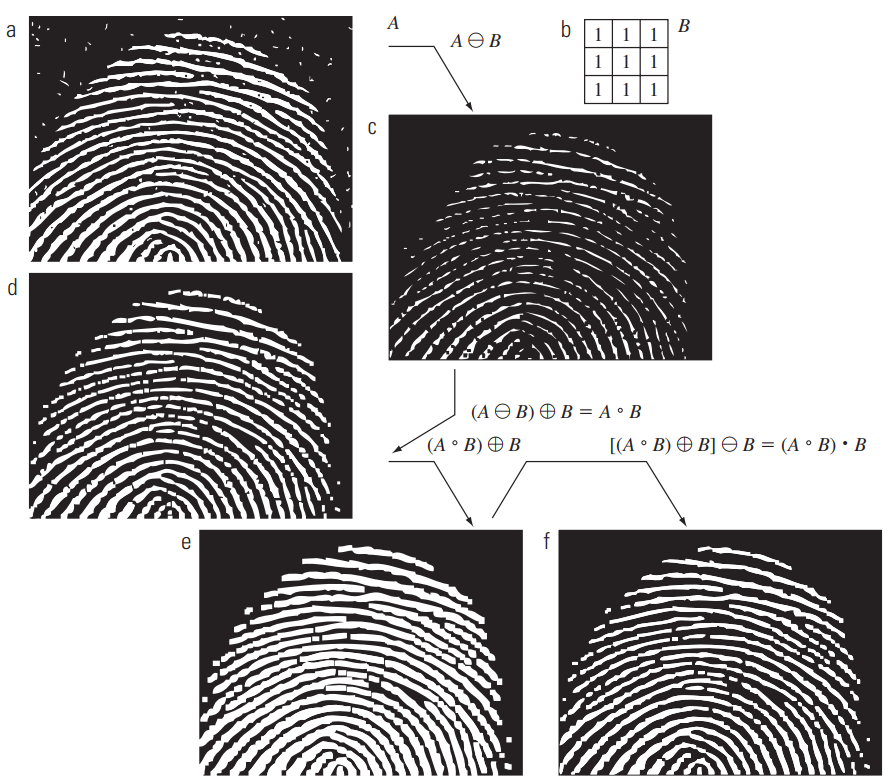

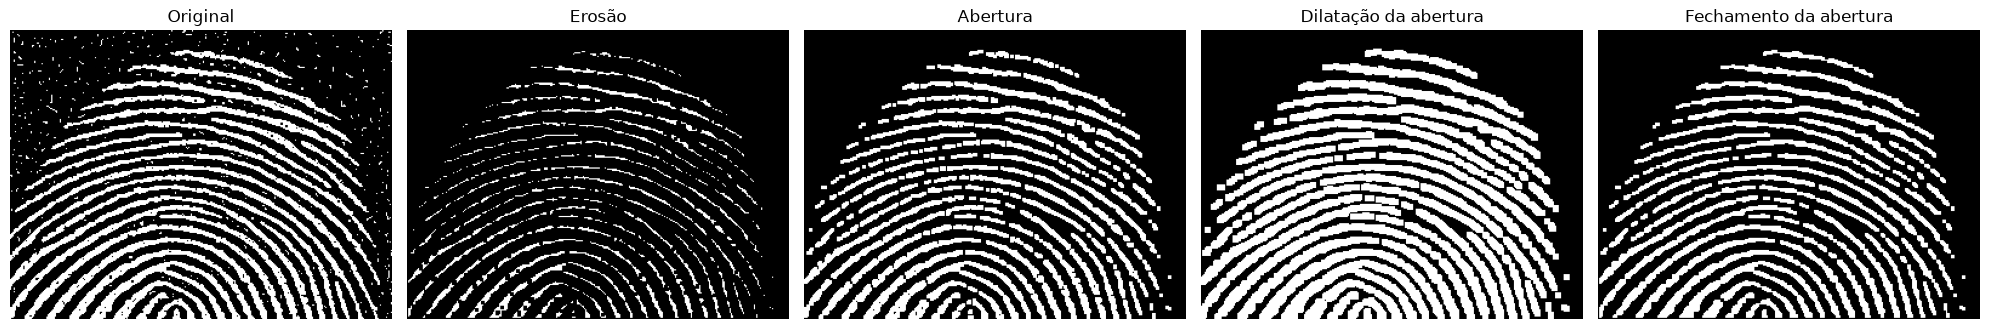

In [4]:
digital = carregar("ImagensMorfologia/Fig0911(a)(noisy_fingerprint).tif")
B = quadrado

erosao_digital = erosao(digital, B)
abertura_digital = abertura(digital, B)
dilatacao_abertura = dilatacao(abertura_digital, B)
fechamento_abertura = fechamento(abertura_digital, B)

mostrar(
    [digital, erosao_digital, abertura_digital, dilatacao_abertura, fechamento_abertura],
    ["Original", "Erosão", "Abertura", "Dilatação da abertura", "Fechamento da abertura"],
)


Na impressão digital, a erosão com o quadrado 3×3 apaga o ruído pontual e também afina e interrompe as cristas. A abertura devolve a espessura das cristas que restaram, sem trazer o ruído de volta, mas as interrupções continuam. A dilatação seguinte engrossa as cristas e junta falhas pequenas, a ponto de algumas se encostarem. O fechamento dessa etapa preenche buracos pequenos e deixa as cristas mais contínuas, com espessura parecida com a da abertura.


## Parte 2 - Filtro Gaussiano na Frequência

Aplicação do filtro Gaussiano passa-baixa na imagem de texto com falhas de 1 e
2 pixels. O código foi adaptado da função `createPB`, no caso `lpType=2`, e da
filtragem com DFT do professor em `refs/Respostas Filtragem na Frequência.ipynb`.

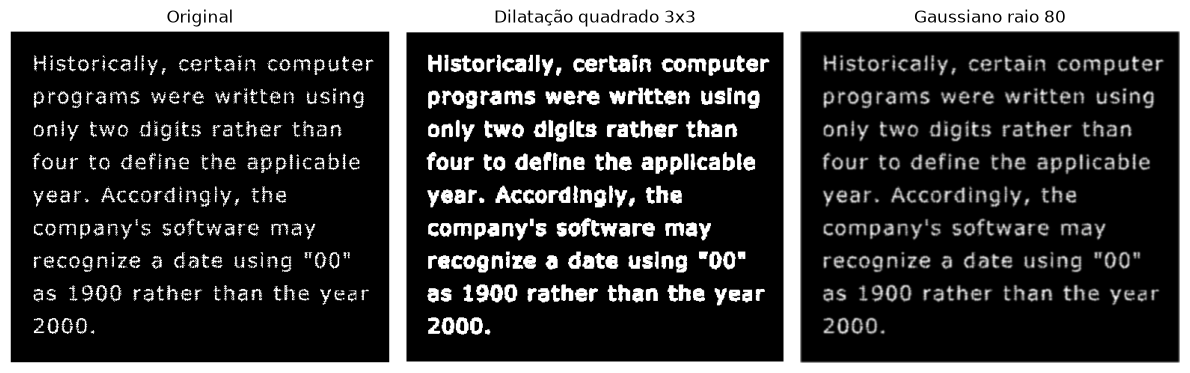

In [5]:
import cv2


# Caso Gaussiano da função createPB.
def createPB(shape, center, radius):
    rows, cols = shape[:2]
    r, c = np.mgrid[0:rows:1, 0:cols:1]
    c -= center[0]
    r -= center[1]
    d = np.power(c, 2.0) + np.power(r, 2.0)
    lpFilter = np.exp(-d / (2 * pow(radius, 2.0)))
    lpFilter_matrix = np.zeros(shape, np.float32)
    lpFilter_matrix[:, :, 0] = lpFilter
    lpFilter_matrix[:, :, 1] = lpFilter
    return lpFilter_matrix


def gaussiano_frequencia(imagem, raio):
    image_f32 = np.float32(imagem)
    dft = cv2.dft(image_f32, flags=cv2.DFT_COMPLEX_OUTPUT)
    dft_shift = np.fft.fftshift(dft, axes=(0, 1))

    rows, cols = imagem.shape
    maskPB = createPB(dft_shift.shape, center=(cols // 2, rows // 2), radius=raio)
    filtered_freq = dft_shift * maskPB
    f_ishift = np.fft.ifftshift(filtered_freq, axes=(0, 1))
    img_back = cv2.idft(f_ishift)
    img_back = cv2.magnitude(img_back[:, :, 0], img_back[:, :, 1])

    # Normalização para 0 a 255, como no código do professor.
    filtered_img = np.abs(img_back)
    filtered_img -= filtered_img.min()
    if filtered_img.max() > 0:
        filtered_img = filtered_img * 255 / filtered_img.max()
    return filtered_img.astype(np.uint8)


texto_gaussiano = gaussiano_frequencia(texto, raio=80)
mostrar(
    [texto, dilatacao_texto, texto_gaussiano],
    ["Original", "Dilatação quadrado 3x3", "Gaussiano raio 80"],
)

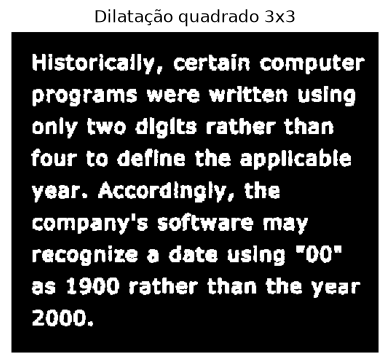

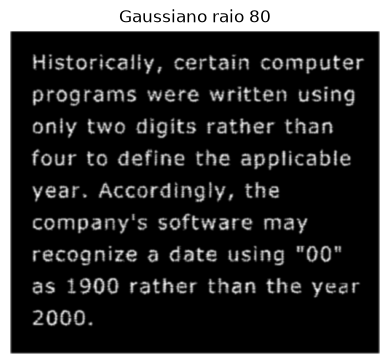

In [6]:
def mostrar_separadas(imagens, titulos):
    for imagem, titulo in zip(imagens, titulos):
        mostrar([imagem], [titulo])


mostrar_separadas(
    [dilatacao_texto, texto_gaussiano],
    ["Dilatação quadrado 3x3", "Gaussiano raio 80"],
)


**Leitura da primeira tentativa (raio 80).** Nesta imagem (508×444 px), o raio 80 no domínio da frequência equivale
a um borrão espacial de cerca de 1 pixel, e a saída continua em tons de cinza. As falhas aparecem como pontos de
brilho menor entre os traços, e a imagem ainda não está "reconstruída" enquanto não for binarizada. A dilatação 3×3,
por sua vez, fecha as falhas, mas engrossa as letras e junta algumas delas.

Essa comparação de um único parâmetro de cada lado é só o ponto de partida. A Parte 3 compara os dois métodos de forma
sistemática, com binarização, varredura de parâmetros, métricas e recorte ampliado.

## Parte 3 - Morfologia × Filtro Gaussiano na reconstrução do texto

**Objetivo.** Comparar o processamento morfológico (código da Parte 1) e o filtro Gaussiano passa-baixa na frequência
(Parte 2) na recuperação do texto com falhas de 1 e 2 pixels.

**Como a comparação é feita**

- **Mesmo critério de saída.** O Gaussiano devolve tons de cinza, então a saída é binarizada com Otsu antes de qualquer
  comparação. Os métodos morfológicos já trabalham com imagem binária.
- **Varredura de parâmetros.** Elementos estruturantes (quadrado 3×3, cruz 3×3, quadrado 5×5) e raios do Gaussiano
  (de 80 a 15), em vez de um único valor de cada.
- **Duas métricas.** (1) *Componentes conexas* (8-vizinhança): um texto sem falhas tem aproximadamente um componente por
  caractere, enquanto falhas quebram letras em vários pedaços e fusões de letras reduzem a contagem. (2) *Razão de área
  branca* em relação ao original: mede o quanto o método engrossa os traços.
- **Região de análise.** A imagem tem uma moldura branca de 1 pixel na borda, que fica de fora das métricas.
- **Faixa de referência.** Não há imagem "gabarito", então a faixa esperada de componentes é estimada contando os
  caracteres do texto. É uma referência aproximada, não um valor exato.

Quanto mais perto da faixa de referência e quanto menor a razão de área, melhor a reconstrução.

In [10]:
import cv2
import pandas as pd
from IPython.display import display
from scipy import ndimage as ndi

elemento_quad3 = quadrado
elemento_cruz3 = cruz
elemento_quad5 = [[1] * 5 for _ in range(5)]


def com_margem(operacao, imagem, elemento):
    """Aplica `operacao` (erosão, dilatação, abertura ou fechamento) com uma margem de zeros ao redor.

    A erosão da Parte 1 trata tudo que está fora da imagem como preto. Como esta imagem tem uma moldura
    branca de 1 pixel na borda, o fechamento sem margem corroeria a moldura. Com a margem, o fechamento
    volta a ser extensivo (contém o original), como manda a teoria."""
    m = len(elemento)
    ampliada = np.pad(imagem, m, constant_values=0)
    return operacao(ampliada, elemento)[m:-m, m:-m]


def binarizar_otsu(imagem_cinza):
    _, binaria = cv2.threshold(imagem_cinza, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return binaria


# Região de análise: ignora a moldura branca da borda.
ROI = (slice(6, -6), slice(6, -6))


def contar_componentes(binaria):
    _, n = ndi.label(binaria[ROI] > 0, structure=np.ones((3, 3)))
    return n


def razao_area(binaria):
    return (binaria[ROI] > 0).sum() / (texto[ROI] > 0).sum()


# Faixa de referência: um componente por caractere (mínimo) até contar também os pontos de "i"/"j"
# e as duas hastes das aspas duplas como componentes separados (máximo).
TEXTO_ORIGINAL = (
    "Historically, certain computer programs were written using only two digits rather than "
    "four to define the applicable year. Accordingly, the company's software may recognize a "
    'date using "00" as 1900 rather than the year 2000.'
)
glifos = [c for c in TEXTO_ORIGINAL if c != " "]
ALVO_MIN = len(glifos)
ALVO_MAX = len(glifos) + sum(c in "ij" for c in glifos) + glifos.count('"')
print(f"Faixa de referência (aproximada): {ALVO_MIN} a {ALVO_MAX} componentes")

# Conferência das implementações da Parte 1 com o OpenCV.
como_uint8 = lambda el: np.array(el, dtype=np.uint8)
assert np.array_equal(dilatacao(texto, quadrado), cv2.dilate(texto, como_uint8(quadrado)))
assert np.array_equal(
    com_margem(fechamento, texto, cruz),
    cv2.morphologyEx(texto, cv2.MORPH_CLOSE, como_uint8(cruz)),
)
print("Dilatação e fechamento conferem com o OpenCV.")

# Efeito da margem no fechamento com cruz 3x3.
sem_margem = fechamento(texto, cruz)
com_m = com_margem(fechamento, texto, cruz)
for nome, f in [("sem margem", sem_margem), ("com margem", com_m)]:
    print(
        f"Fechamento cruz 3x3 {nome}: área ×{(f > 0).sum() / (texto > 0).sum():.2f} do original, "
        f"contém o original: {bool(np.all((f > 0) >= (texto > 0)))}"
    )


Faixa de referência (aproximada): 191 a 205 componentes
Dilatação e fechamento conferem com o OpenCV.
Fechamento cruz 3x3 sem margem: área ×0.97 do original, contém o original: False
Fechamento cruz 3x3 com margem: área ×1.08 do original, contém o original: True


### 3.1 Processamento morfológico

Dilatação e fechamento com três elementos estruturantes, usando as funções `dilatacao` e `fechamento` da Parte 1.
A dilatação cobre as falhas fazendo os traços crescerem. O fechamento (dilatação seguida de erosão) cobre as falhas
e depois devolve a espessura aos traços.

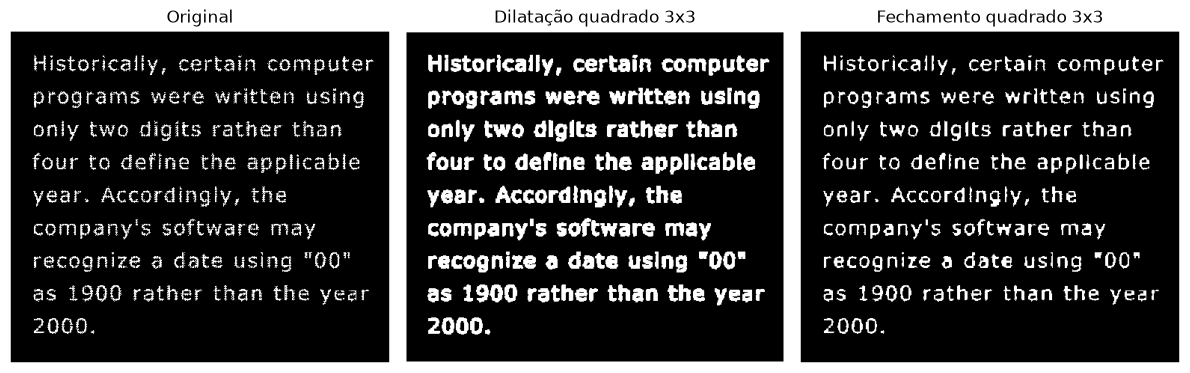

In [11]:
elementos = {
    "quadrado 3x3": elemento_quad3,
    "cruz 3x3": elemento_cruz3,
    "quadrado 5x5": elemento_quad5,
}

resultados = {"Original": texto}
for nome, el in elementos.items():
    resultados[f"Dilatação {nome}"] = dilatacao(texto, el)
    resultados[f"Fechamento {nome}"] = com_margem(fechamento, texto, el)

mostrar(
    [resultados[k] for k in ["Original", "Dilatação quadrado 3x3", "Fechamento quadrado 3x3"]],
    ["Original", "Dilatação quadrado 3x3", "Fechamento quadrado 3x3"],
)


### 3.2 Filtro Gaussiano na frequência, com binarização

O raio do filtro está no domínio da frequência: **quanto maior o raio, menor o borrão no espaço**. O desvio-padrão
espacial equivalente é aproximadamente `largura / (2π · raio)`. A saída em cinza é binarizada com Otsu.

raio 80: desvio-padrão espacial ≈ 1.0 px
raio 60: desvio-padrão espacial ≈ 1.3 px
raio 50: desvio-padrão espacial ≈ 1.6 px
raio 40: desvio-padrão espacial ≈ 2.0 px
raio 35: desvio-padrão espacial ≈ 2.3 px
raio 30: desvio-padrão espacial ≈ 2.7 px
raio 25: desvio-padrão espacial ≈ 3.2 px
raio 15: desvio-padrão espacial ≈ 5.4 px


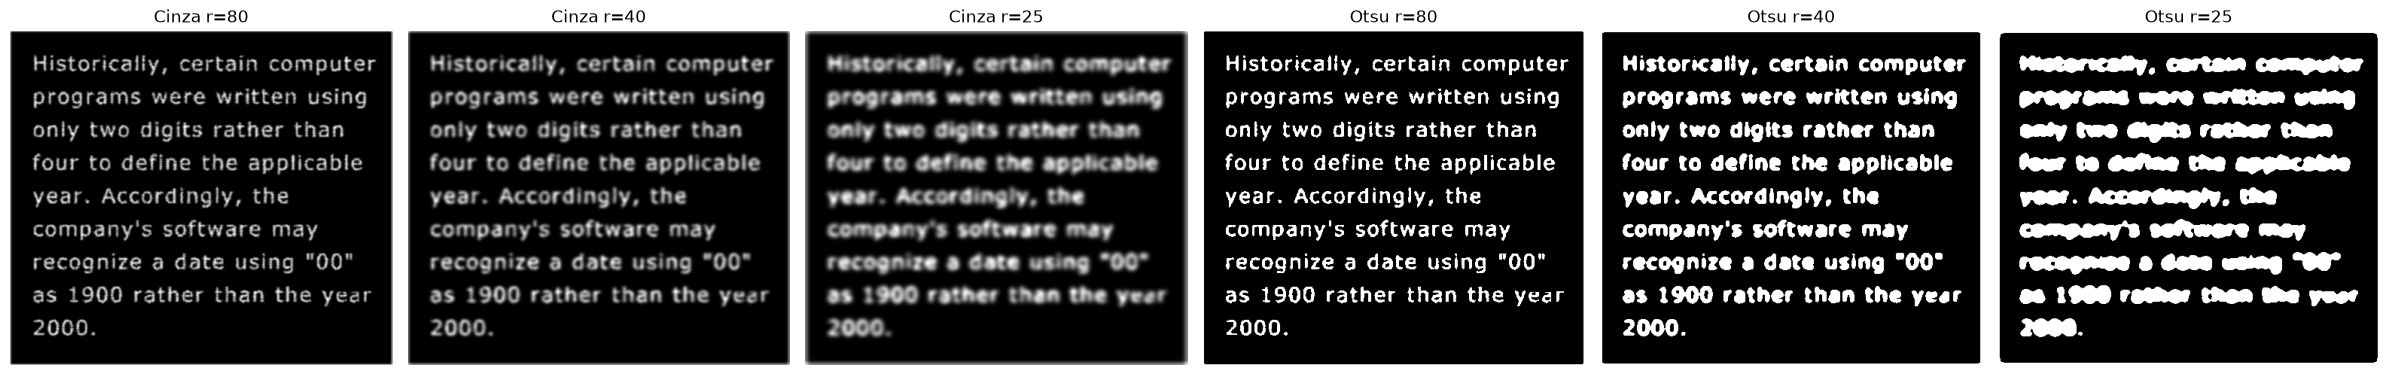

In [12]:
raios = [80, 60, 50, 40, 35, 30, 25, 15]
largura = texto.shape[1]

gaussianos_cinza = {}
for r in raios:
    cinza = gaussiano_frequencia(texto, r)
    gaussianos_cinza[r] = cinza
    resultados[f"Gaussiano r={r} + Otsu"] = binarizar_otsu(cinza)
    print(f"raio {r:>2}: desvio-padrão espacial ≈ {largura / (2 * np.pi * r):.1f} px")

# Híbrido: Gaussiano binarizado seguido de fechamento com cruz 3x3.
resultados["Híbrido: Gaussiano r=80 + Otsu + fechamento cruz 3x3"] = com_margem(
    fechamento, resultados["Gaussiano r=80 + Otsu"], elemento_cruz3
)

mostrar(
    [gaussianos_cinza[r] for r in (80, 40, 25)] + [resultados[f"Gaussiano r={r} + Otsu"] for r in (80, 40, 25)],
    [f"Cinza r={r}" for r in (80, 40, 25)] + [f"Otsu r={r}" for r in (80, 40, 25)],
)


### 3.3 Comparação quantitativa

Componentes conexas e razão de área para todas as variantes. No gráfico, a faixa cinza é a referência aproximada de
componentes. O melhor resultado fica dentro da faixa e o mais à esquerda possível.

,Método,Componentes,Área vs original
0,Original,265,1.00
1,Dilatação quadrado 3x3,185,2.30
2,Fechamento quadrado 3x3,195,1.23
3,Dilatação cruz 3x3,193,1.93
4,Fechamento cruz 3x3,219,1.09
5,Dilatação quadrado 5x5,110,3.39
6,Fechamento quadrado 5x5,135,1.44
7,Gaussiano r=80 + Otsu,204,1.47
8,Gaussiano r=60 + Otsu,200,1.75
9,Gaussiano r=50 + Otsu,197,1.94


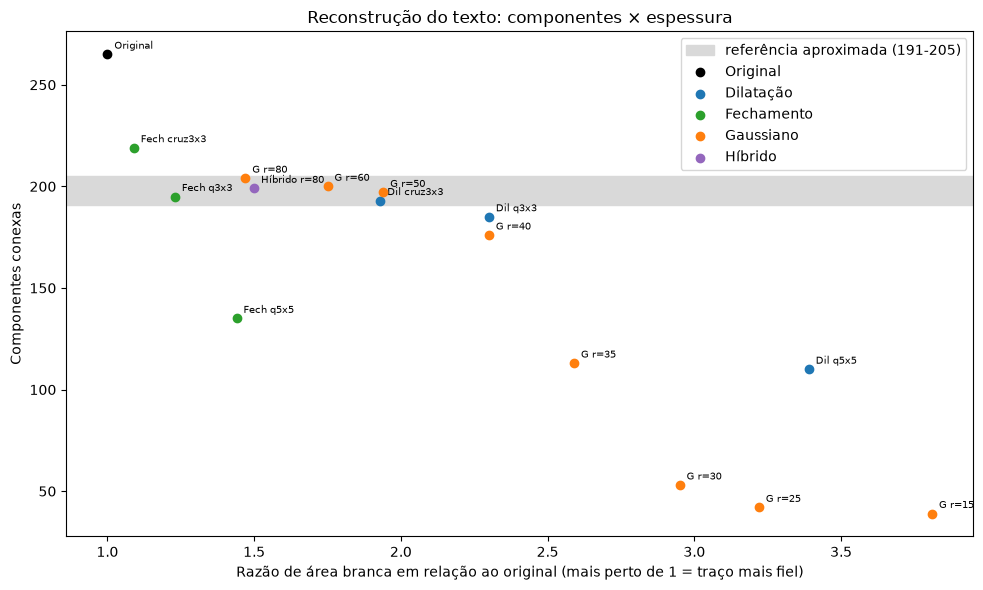

In [13]:
linhas = []
for nome, img in resultados.items():
    linhas.append(
        {
            "Método": nome,
            "Componentes": contar_componentes(img),
            "Área vs original": round(float(razao_area(img)), 2),
        }
    )
tabela = pd.DataFrame(linhas)
display(tabela)

cores = {"Original": "black", "Dilatação": "tab:blue", "Fechamento": "tab:green", "Gaussiano": "tab:orange", "Híbrido": "tab:purple"}
fig, eixo = plt.subplots(figsize=(10, 6))
eixo.axhspan(ALVO_MIN, ALVO_MAX, color="0.85", label=f"referência aproximada ({ALVO_MIN}-{ALVO_MAX})")
for _, linha in tabela.iterrows():
    familia = linha["Método"].split()[0].rstrip(":")
    eixo.scatter(linha["Área vs original"], linha["Componentes"], color=cores[familia], zorder=3)
    rotulo = (
        linha["Método"]
        .replace("Híbrido: Gaussiano r=80 + Otsu + fechamento cruz 3x3", "Híbrido r=80")
        .replace("Gaussiano ", "G ")
        .replace(" + Otsu", "")
        .replace("Dilatação ", "Dil ")
        .replace("Fechamento ", "Fech ")
        .replace("quadrado ", "q")
        .replace("cruz ", "cruz")
    )
    eixo.annotate(rotulo, (linha["Área vs original"], linha["Componentes"]), textcoords="offset points", xytext=(5, 4), fontsize=7)
for familia, cor in cores.items():
    eixo.scatter([], [], color=cor, label=familia)
eixo.set_xlabel("Razão de área branca em relação ao original (mais perto de 1 = traço mais fiel)")
eixo.set_ylabel("Componentes conexas")
eixo.set_title("Reconstrução do texto: componentes × espessura")
eixo.legend(loc="upper right")
plt.tight_layout()
plt.show()


### 3.4 Comparação visual (recorte ampliado)

Um trecho das duas primeiras linhas, com os principais métodos lado a lado.

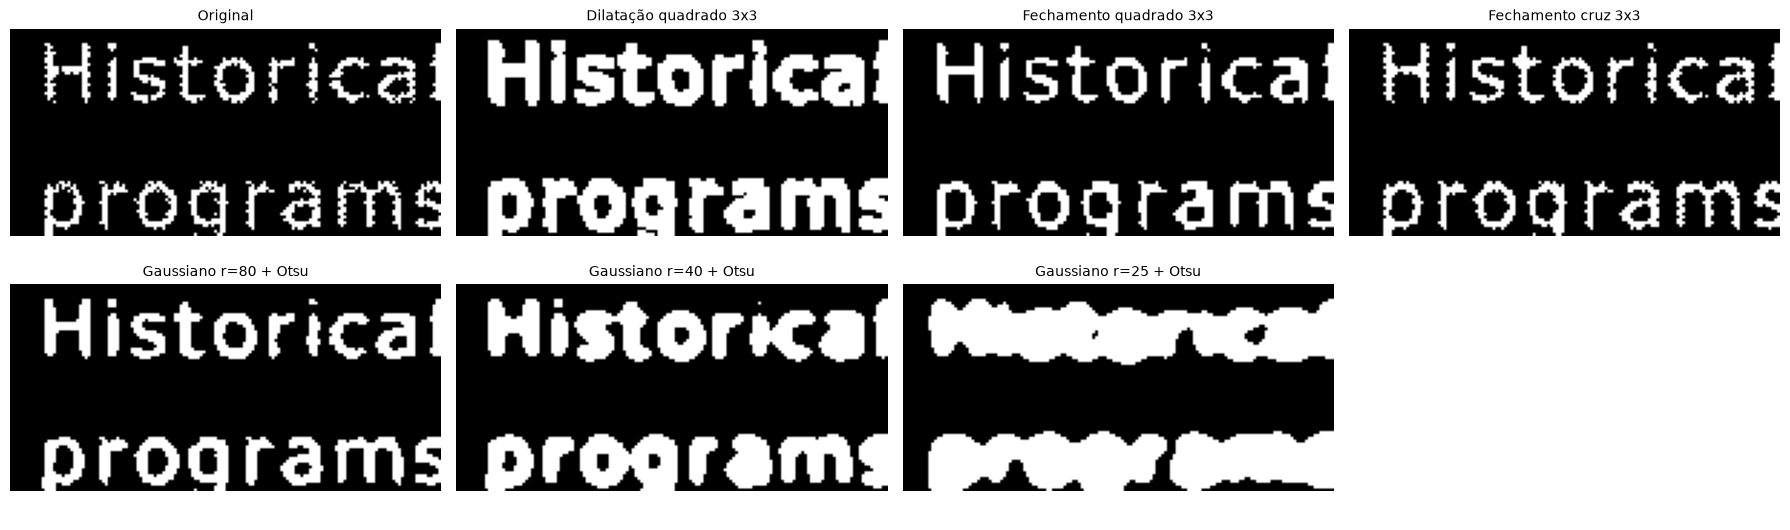

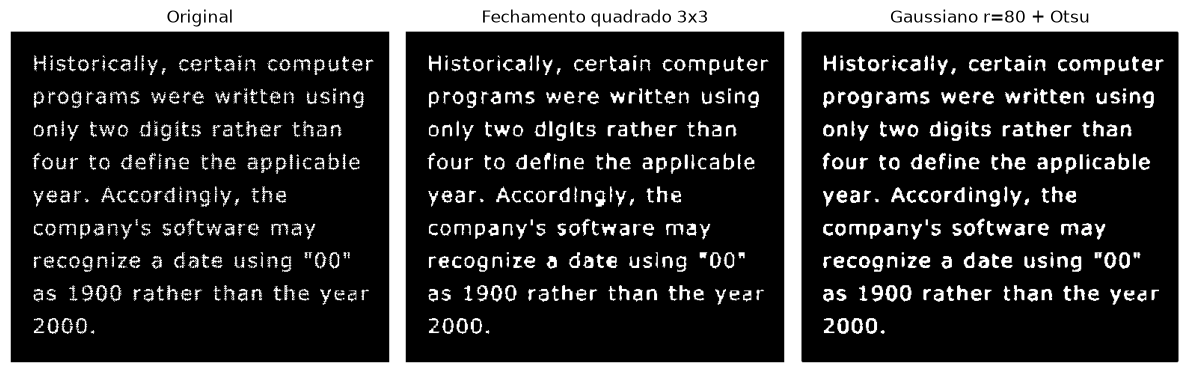

In [14]:
recorte = (slice(28, 100), slice(20, 170))
painel = [
    "Original",
    "Dilatação quadrado 3x3",
    "Fechamento quadrado 3x3",
    "Fechamento cruz 3x3",
    "Gaussiano r=80 + Otsu",
    "Gaussiano r=40 + Otsu",
    "Gaussiano r=25 + Otsu",
]
fig, eixos = plt.subplots(2, 4, figsize=(18, 5.5))
for eixo, nome in zip(eixos.ravel(), painel):
    eixo.imshow(resultados[nome][recorte], cmap="gray", vmin=0, vmax=255)
    eixo.set_title(nome, fontsize=10)
    eixo.axis("off")
eixos.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

mostrar(
    [texto, resultados["Fechamento quadrado 3x3"], resultados["Gaussiano r=80 + Otsu"]],
    ["Original", "Fechamento quadrado 3x3", "Gaussiano r=80 + Otsu"],
)


### 3.5 Análise conjunta

Números principais da tabela (região interna, sem a moldura). A faixa de referência é de 191 a 205 componentes, e o original tem 265 porque as falhas quebram as letras.

| Método | Componentes | Área vs original |
|---|---|---|
| Fechamento quadrado 3×3 | 195 | ×1,23 |
| Gaussiano r=80 + Otsu | 204 | ×1,47 |
| Dilatação quadrado 3×3 | 185 | ×2,30 |
| Fechamento cruz 3×3 | 219 | ×1,09 |
| Gaussiano r=40 + Otsu | 176 | ×2,30 |
| Gaussiano r=30 + Otsu | 53 | ×2,95 |

**1. O Gaussiano só reconstrói depois do limiar.** Em tons de cinza, o filtro apenas suaviza: as falhas viram vales de brilho entre os traços, mas continuam lá. A reconstrução aparece quando o Otsu transforma esses vales em branco. O processamento morfológico, ao contrário, atua direto na imagem binária e fecha as falhas pela forma do elemento estruturante.

**2. Para falhas pequenas, os dois funcionam, com custos diferentes.** O fechamento quadrado 3×3 (195 componentes) e o Gaussiano com raio 80 (204) ficam dentro da faixa de referência. O fechamento engrossa pouco os traços (×1,23), e no recorte as letras mantêm a espessura e a separação do original. O Gaussiano deixa os traços mais grossos (×1,47).

**3. A dilatação fecha as falhas, mas paga em espessura.** Com o quadrado 3×3, a área sobe ×2,30 e a contagem cai a 185, abaixo da faixa, porque as letras engrossam e começam a se juntar. O fechamento (dilatação seguida de erosão) resolve as mesmas falhas sem engrossar o texto: 195 componentes com ×1,23, contra 185 com ×2,30.

**4. Os dois métodos têm um ponto em que deixam de fechar falhas e passam a fundir letras.** No fechamento, ele fica entre o quadrado 3×3 (195) e o 5×5 (135). No Gaussiano, entre r=40 (176) e r=30 (53), que corresponde a um desvio-padrão espacial de 2,0 a 2,7 px. Nesse ponto as letras viram palavras, como se vê no recorte com r=25. No Gaussiano, a espessura também cresce a cada redução do raio (×1,47 em r=80, ×1,94 em r=50, ×2,30 em r=40).

**5. A forma do elemento estruturante importa.** Com o mesmo tamanho 3×3, o quadrado deixa 195 componentes e a cruz deixa 219, acima da faixa, o que indica falhas que a cruz não fecha. A cruz preserva melhor a espessura (×1,09), mas o contorno das letras continua irregular no recorte.

**6. O método híbrido não compensa.** Gaussiano r=80 + Otsu + fechamento com cruz dá 199 componentes e ×1,50, praticamente o mesmo resultado do Gaussiano sozinho (204 e ×1,47). A etapa extra não traz ganho.

**Conclusão.** Para esta imagem, o fechamento com quadrado 3×3 é o melhor custo-benefício: reconstrói o texto dentro da faixa de referência e é o que menos engrossa os traços entre os métodos que fecham as falhas. O Gaussiano com raio em torno de 80 e binarização por Otsu é uma alternativa competitiva, mas engrossa mais, depende do limiar e exige DFT da imagem inteira, enquanto o fechamento usa só operações locais. A dilatação sozinha também fecha as falhas, mas engrossa demais.

**Limitações.** (a) Não há imagem "gabarito": a faixa de referência vem da contagem de caracteres do texto e é aproximada. (b) As métricas medem conectividade e espessura, não a fidelidade do formato das letras, que foi avaliada só visualmente no recorte. (c) Foi usada uma única imagem e o Otsu para escolher o limiar automaticamente; outros limiares mudariam os números do Gaussiano.